# Lifestyle, Sleep and Screen-Time Risk Factors for Dry Eye Disease
### A data science project: data audit, statistical analysis, and machine learning

**Author:** Festus Kofi Boateng Otchere, Technologist, Eye Centre (Korle Bu), Ghana
**Date:** 24th October 2026
**Dataset:** *Dry Eye Disease* on Kaggle (author handle: dakshnagra), 20,000 rows and 26 columns

---

### Abstract
Dry eye disease (DED) is a common condition of the eye surface in which tears are too few or evaporate too quickly, causing dryness, redness, itching and discomfort. More hours on screens and poor sleep are widely suspected to make it worse. This project uses a 20,000-person dataset to ask which lifestyle and health factors are linked to DED, how strong those links really are, and whether a model can estimate a person's DED risk from lifestyle information alone, before symptoms appear.

The workflow follows the full data science cycle: **data audit, cleaning and feature engineering, exploratory analysis, statistical testing (with correction for multiple comparisons), multivariable regression, machine learning with cross-validation, honest evaluation on unseen data, explainability, subgroup checks, and clinical recommendations.**

> This is a learning and research project. It is **not** a diagnostic tool and does not replace a clinical eye examination.

## Table of contents
0. Setup
1. Data loading and audit (is the data clean and believable?)
2. Cleaning and feature engineering
3. Exploratory data analysis (EDA)
4. Statistical testing (which links are real, and how big?)
5. Multivariable regression (adjusting for everything at once)
6. Machine learning (can we predict DED?)
7. Explainability (what is the model using?)
8. Subgroup (fairness) check
9. Summary, limitations and recommendations
10. Export for Power BI

### Questions this project answers
1. How common is DED in this sample?
2. Which lifestyle and health factors are linked to DED?
3. Are those links strong enough to matter in practice, or only "statistically significant"?
4. Can machine learning predict DED from lifestyle information alone (before symptoms)? Does adding symptoms help?
5. What should an eye centre do with these results?

## Data dictionary
The dataset has no official data dictionary, so the units below are **assumptions** based on the values. Confirm them with the dataset author before publishing.

| Column | Meaning (assumed) | Values |
|---|---|---|
| Gender | Sex of the person | F / M |
| Age | Age in years | 18 to 45 |
| Sleep duration | Hours slept per night | 4 to 10 |
| Sleep quality | Self-rated sleep quality score | 1 to 5 |
| Stress level | Self-rated stress score | 1 to 5 |
| Blood pressure | Systolic/diastolic text, e.g. 120/80 (mmHg) | text |
| Heart rate | Beats per minute | 60 to 100 |
| Daily steps | Steps per day | 1,000 to 20,000 |
| Physical activity | Minutes of activity per day | 0 to 180 |
| Height / Weight | cm / kg | numbers |
| Sleep disorder, Wake up during night, Feel sleepy during day | Sleep problems | Y / N |
| Caffeine, Alcohol, Smoking | Habits | Y / N |
| Medical issue, Ongoing medication | Health background | Y / N |
| Smart device before bed, Blue-light filter | Screen habits | Y / N |
| Average screen time | Hours per day on screens | 1 to 10 |
| Discomfort Eye-strain, Redness in eye, Itchiness/Irritation in eye | **Eye symptoms** | Y / N |
| **Dry Eye Disease** | **Target: does the person have DED?** | Y / N |

## Part 0: Setup

In [1]:
import os, re, glob, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, f1_score, accuracy_score, balanced_accuracy_score)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42                      # fixed seed so anyone re-running gets the same results
TARGET = "dry_eye_disease"     # the column we want to understand and predict
COLORS = {0: "#4C78A8", 1: "#E45756"}   # blue = no DED, red = DED
np.random.seed(SEED)
print("Setup complete.")

Setup complete.


## Part 1: Data loading and audit
Before any analysis, we check that the data is **complete, valid and believable**. A model built on bad data gives confident but wrong answers.

In [2]:
# Find the CSV file automatically (Kaggle input folder, or the current folder on your own computer).
DATA_PATH = None   # or type the path yourself, e.g. "Dry_Eye_Dataset.csv"

def snake(name):
    return re.sub(r"[^0-9a-zA-Z]+", "_", name.strip()).strip("_").lower()

def find_dataset():
    # Look for CSV files, and accept only one that really has the 'Dry Eye Disease' column
    # (this also avoids picking up files this notebook saved earlier).
    hits = []
    for pattern in ["/kaggle/input/**/*.csv", "./*.csv", "./**/*.csv"]:
        hits += glob.glob(pattern, recursive=True)
    for h in hits:
        try:
            header = pd.read_csv(h, nrows=0).columns
        except Exception:
            continue
        if TARGET in [snake(c) for c in header] and "blood_pressure" in [snake(c) for c in header]:
            return h
    raise FileNotFoundError("Dry eye CSV not found. On Kaggle click 'Add Input' and add the Dry Eye Disease dataset.")

DATA_PATH = DATA_PATH or find_dataset()
raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Rows and columns:", raw.shape)
raw.head()

Loaded: .\Dry_Eye_Dataset.csv
Rows and columns: (20000, 26)


,Gender,Age,Sleep duration,Sleep quality,Stress level,Blood pressure,Heart rate,Daily steps,Physical activity,Height,...,Smoking,Medical issue,Ongoing medication,Smart device before bed,Average screen time,Blue-light filter,Discomfort Eye-strain,Redness in eye,Itchiness/Irritation in eye,Dry Eye Disease
0,F,24,9.5,2,1,137/89,67,3000,31,161,...,N,Y,Y,N,8.7,N,Y,Y,N,Y
1,M,39,9.6,2,3,108/64,60,12000,74,164,...,N,Y,Y,N,9.6,Y,N,N,Y,Y
2,F,45,5.4,1,5,134/81,95,12000,93,179,...,N,N,N,Y,4.0,N,Y,N,N,N
3,F,45,5.4,4,5,110/90,78,19000,32,160,...,N,Y,N,N,7.6,N,Y,N,Y,N
4,F,42,5.7,3,2,99/67,72,4000,173,179,...,N,Y,N,N,3.5,N,Y,Y,N,Y


In [3]:
# Tidy column names: "Itchiness/Irritation in eye" -> "itchiness_irritation_in_eye"
df = raw.copy()
df.columns = [snake(c) for c in df.columns]
assert TARGET in df.columns, f"Target column '{TARGET}' not found. Columns are: {list(df.columns)}"

print("Column types:")
display(df.dtypes.astype(str).to_frame("type").T)

print("Missing values per column (should all be 0):")
print(df.isna().sum()[lambda s: s > 0].to_string() or "None missing")
print("\nDuplicate rows:", df.duplicated().sum())
print("Number of distinct values per column:")
display(df.nunique().to_frame("distinct_values").T)

Column types:


,gender,age,sleep_duration,sleep_quality,stress_level,blood_pressure,heart_rate,daily_steps,physical_activity,height,...,smoking,medical_issue,ongoing_medication,smart_device_before_bed,average_screen_time,blue_light_filter,discomfort_eye_strain,redness_in_eye,itchiness_irritation_in_eye,dry_eye_disease
type,str,int64,float64,int64,int64,str,int64,int64,int64,int64,...,str,str,str,str,float64,str,str,str,str,str


Missing values per column (should all be 0):
Series([], )

Duplicate rows: 0
Number of distinct values per column:


,gender,age,sleep_duration,sleep_quality,stress_level,blood_pressure,heart_rate,daily_steps,physical_activity,height,...,smoking,medical_issue,ongoing_medication,smart_device_before_bed,average_screen_time,blue_light_filter,discomfort_eye_strain,redness_in_eye,itchiness_irritation_in_eye,dry_eye_disease
distinct_values,2,28,61,5,5,1581,41,20,181,51,...,2,2,2,2,91,2,2,2,2,2


In [4]:
# Validity check: are the values physically possible?
# Wide limits are used so that only impossible values (e.g. age 400) are flagged.
limits = {"age": (10, 100), "sleep_duration": (0, 24), "sleep_quality": (1, 5), "stress_level": (1, 5),
          "heart_rate": (30, 220), "daily_steps": (0, 60000), "physical_activity": (0, 1440),
          "height": (100, 230), "weight": (25, 300), "average_screen_time": (0, 24)}
rows = []
for col, (lo, hi) in limits.items():
    if col in df.columns:
        bad = ((df[col] < lo) | (df[col] > hi)).sum()
        rows.append({"column": col, "min": df[col].min(), "max": df[col].max(), "impossible_values": int(bad)})
display(pd.DataFrame(rows))

# Yes/No columns must contain only Y or N
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() <= 3:
        print(f"{c:32s} values: {sorted(df[c].dropna().unique())}")

,column,min,max,impossible_values
0,age,18.0,45.0,0
1,sleep_duration,4.0,10.0,0
2,sleep_quality,1.0,5.0,0
3,stress_level,1.0,5.0,0
4,heart_rate,60.0,100.0,0
5,daily_steps,1000.0,20000.0,0
6,physical_activity,0.0,180.0,0
7,height,150.0,200.0,0
8,weight,50.0,100.0,0
9,average_screen_time,1.0,10.0,0


gender                           values: ['F', 'M']
sleep_disorder                   values: ['N', 'Y']
wake_up_during_night             values: ['N', 'Y']
feel_sleepy_during_day           values: ['N', 'Y']
caffeine_consumption             values: ['N', 'Y']
alcohol_consumption              values: ['N', 'Y']
smoking                          values: ['N', 'Y']
medical_issue                    values: ['N', 'Y']
ongoing_medication               values: ['N', 'Y']
smart_device_before_bed          values: ['N', 'Y']
blue_light_filter                values: ['N', 'Y']
discomfort_eye_strain            values: ['N', 'Y']
redness_in_eye                   values: ['N', 'Y']
itchiness_irritation_in_eye      values: ['N', 'Y']
dry_eye_disease                  values: ['N', 'Y']


### Does this data behave like real patients? (a data-integrity check)
In real populations, measurements such as age, heart rate or weight usually cluster around a typical value (a bell shape). Here we compute a **uniformity index**: the observed spread divided by the spread of a perfectly flat (uniform) distribution.

- A value near **1.0** means the values are spread **evenly** across the whole range, like numbers drawn from a random-number generator.
- Real clinical measurements usually give **0.6 to 0.8**.

If most columns are near 1.0, the data may be **simulated or synthetic**. That does not make the project useless (the techniques are the same), but it means conclusions are *illustrative* and must be confirmed on real clinic data before any clinical claim.

column,age,sleep_duration,heart_rate,daily_steps,physical_activity,height,weight,average_screen_time
uniformity_index,1.04,1.0,1.02,1.05,1.01,1.02,1.02,1.0


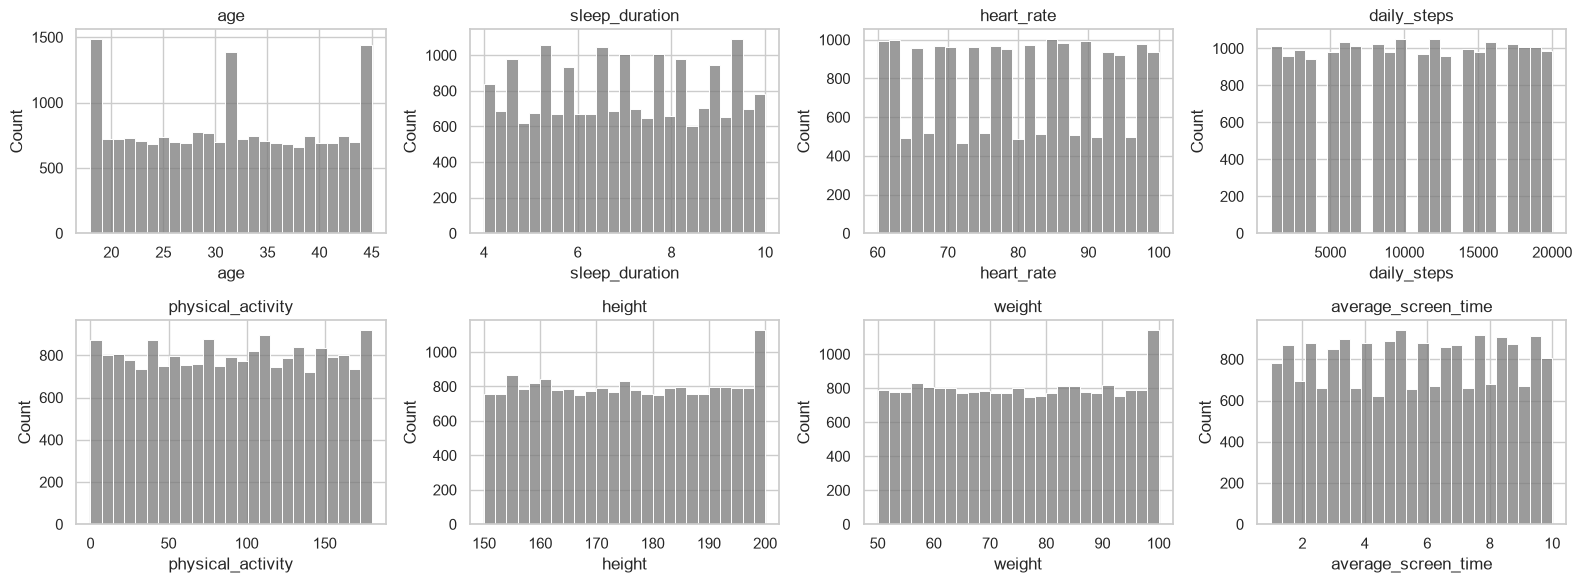

100% of the checked columns are almost perfectly flat.


In [5]:
num_check = [c for c in ["age", "sleep_duration", "heart_rate", "daily_steps", "physical_activity", "height", "weight", "average_screen_time"] if c in df.columns]
rows = []
for c in num_check:
    spread_flat = (df[c].max() - df[c].min()) / np.sqrt(12)
    rows.append({"column": c, "uniformity_index": round(df[c].std() / spread_flat, 2)})
unif = pd.DataFrame(rows).set_index("column")
display(unif.T)

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), num_check):
    sns.histplot(df[c], bins=25, ax=ax, color="#7A7A7A"); ax.set_title(c)
plt.tight_layout(); plt.show()

share_flat = (unif.uniformity_index > 0.9).mean()
print(f"{share_flat:.0%} of the checked columns are almost perfectly flat.")
if share_flat > 0.6:
    print("WARNING: the data looks synthetic. Treat findings as exploratory and illustrative.")

## Part 2: Cleaning and feature engineering
**Feature engineering** means creating more useful columns from the ones we have.

| New column | How it is made | Why it helps |
|---|---|---|
| Y/N columns as 1/0 | Y becomes 1, N becomes 0 | Computers need numbers |
| `systolic`, `diastolic` | Split "120/80" into two numbers | Blood pressure text cannot be analysed directly |
| `bmi` | weight (kg) divided by height (m) squared | One number that combines height and weight |
| `high_bp` | systolic at least 140 or diastolic at least 90 | A simple clinical flag |
| `age_group`, `screen_group`, `sleep_group`, `bmi_group` | Numbers cut into bands | Easier to chart and explain |

In [6]:
# 1) Turn every Y/N column into 1/0
yn_cols = [c for c in df.columns
           if not pd.api.types.is_numeric_dtype(df[c]) and df[c].dropna().isin(["Y", "N"]).all()]
for c in yn_cols:
    df[c] = (df[c] == "Y").astype(int)

# 2) Split blood pressure "137/89" into two numbers
bp = df["blood_pressure"].str.extract(r"(\d+)\s*/\s*(\d+)").astype(float)
print("Blood pressure values that could not be read:", int(bp.isna().any(axis=1).sum()))
df["systolic"], df["diastolic"] = bp[0], bp[1]
df["high_bp"] = ((df.systolic >= 140) | (df.diastolic >= 90)).astype(int)

# 3) Body mass index
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2

# 4) Bands for easy charts (ordered categories)
df["age_group"] = pd.cut(df.age, [17, 25, 35, 45], labels=["18-25", "26-35", "36-45"])
df["screen_group"] = pd.cut(df.average_screen_time, [0, 3, 6, 8, 10.01], labels=["0-3h", "3-6h", "6-8h", "8-10h"])
df["sleep_group"] = pd.cut(df.sleep_duration, [0, 6, 8, 11], labels=["6h or less", "6-8h", "over 8h"])
df["bmi_group"] = pd.cut(df.bmi, [0, 18.5, 25, 30, 100], labels=["Underweight", "Normal", "Overweight", "Obese"])

# 5) Lists of columns we will reuse
SYMPTOMS = [c for c in ["discomfort_eye_strain", "redness_in_eye", "itchiness_irritation_in_eye"] if c in df.columns]
BIN_ALL = [c for c in yn_cols if c != TARGET] + ["high_bp"]       # all yes/no predictors
BIN_LIFESTYLE = [c for c in BIN_ALL if c not in SYMPTOMS]          # yes/no predictors without eye symptoms
NUM_ALL = [c for c in ["age", "sleep_duration", "sleep_quality", "stress_level", "heart_rate", "daily_steps",
                       "physical_activity", "height", "weight", "bmi", "systolic", "diastolic", "average_screen_time"] if c in df.columns]
NUM_ML = [c for c in NUM_ALL if c not in ("height", "weight")]    # BMI already combines height and weight

print("Yes/No columns:", len(yn_cols), "| symptom columns:", SYMPTOMS)
df.head()

Blood pressure values that could not be read: 0
Yes/No columns: 14 | symptom columns: ['discomfort_eye_strain', 'redness_in_eye', 'itchiness_irritation_in_eye']


,gender,age,sleep_duration,sleep_quality,stress_level,blood_pressure,heart_rate,daily_steps,physical_activity,height,...,itchiness_irritation_in_eye,dry_eye_disease,systolic,diastolic,high_bp,bmi,age_group,screen_group,sleep_group,bmi_group
0,F,24,9.5,2,1,137/89,67,3000,31,161,...,0,1,137.0,89.0,0,26.619343,18-25,8-10h,over 8h,Overweight
1,M,39,9.6,2,3,108/64,60,12000,74,164,...,1,1,108.0,64.0,0,32.346817,36-45,8-10h,over 8h,Obese
2,F,45,5.4,1,5,134/81,95,12000,93,179,...,0,0,134.0,81.0,0,29.337411,36-45,3-6h,6h or less,Overweight
3,F,45,5.4,4,5,110/90,78,19000,32,160,...,1,0,110.0,90.0,1,30.078125,36-45,6-8h,6h or less,Obese
4,F,42,5.7,3,2,99/67,72,4000,173,179,...,0,1,99.0,67.0,0,30.897912,36-45,3-6h,6h or less,Obese


## Part 3: Exploratory data analysis (EDA)
EDA means looking at the data from many angles to learn its shape before testing anything.

### 3.1 How common is dry eye disease in this sample?

DED prevalence: 65.2% (95% confidence range 64.5% to 65.8%) in 20,000 people
A model that always answers 'no DED' or 'DED' (whichever is more common) would be right 65.2% of the time.
That is the BASELINE any model must beat.


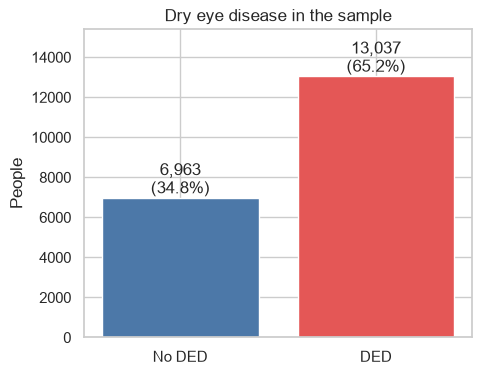

In [7]:
prevalence = df[TARGET].mean()
n_total = len(df)
lo, hi = proportion_confint(df[TARGET].sum(), n_total, method="wilson")
print(f"DED prevalence: {prevalence:.1%} (95% confidence range {lo:.1%} to {hi:.1%}) in {n_total:,} people")
print(f"A model that always answers 'no DED' or 'DED' (whichever is more common) would be right {max(prevalence, 1-prevalence):.1%} of the time.")
print("That is the BASELINE any model must beat.")

fig, ax = plt.subplots(figsize=(5, 4))
counts = df[TARGET].value_counts().sort_index()
ax.bar(["No DED", "DED"], counts.values, color=[COLORS[0], COLORS[1]])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/n_total:.1%})", ha="center", va="bottom")
ax.set_ylabel("People"); ax.set_title("Dry eye disease in the sample"); ax.set_ylim(0, counts.max() * 1.18)
plt.show()

### 3.2 Distributions of the measurements, split by DED status
Where the red and blue curves differ, that measurement may carry information about DED. Heavy overlap means it is not very useful by itself.

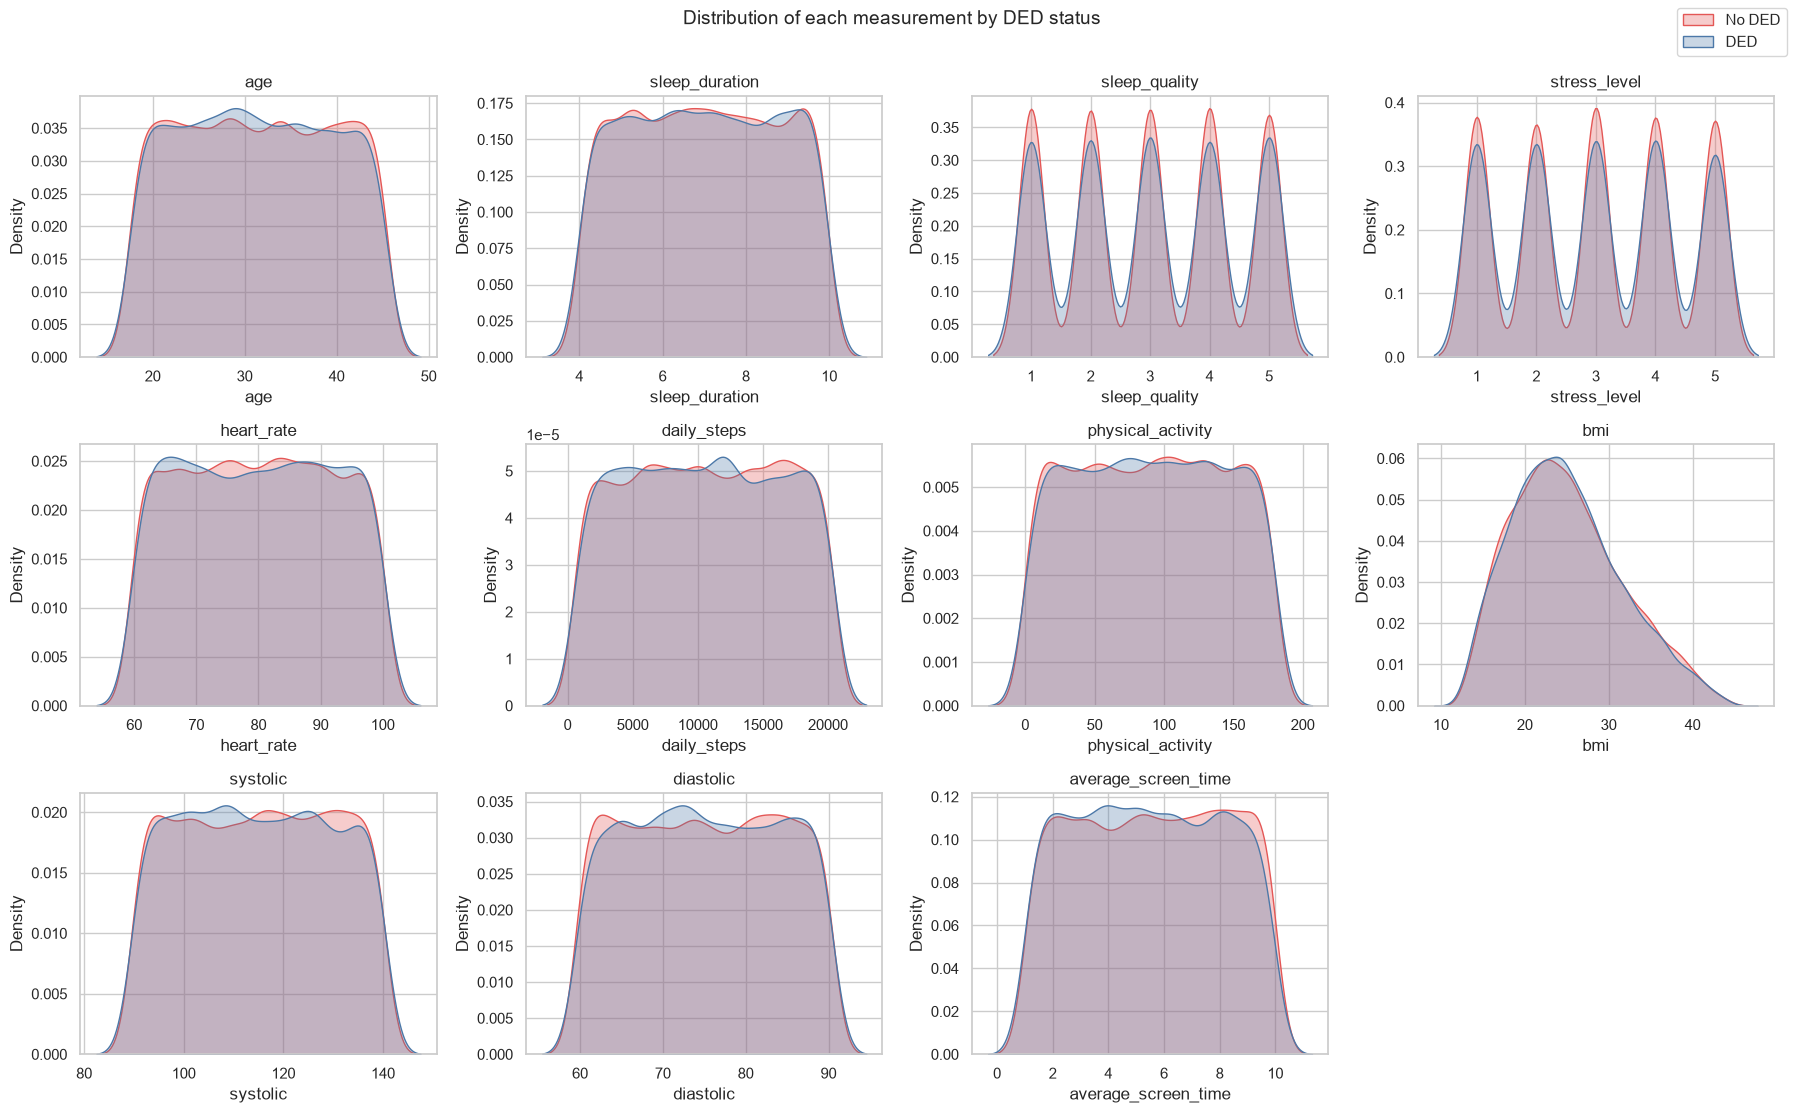

In [8]:
cols = [c for c in NUM_ML]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), cols):
    sns.kdeplot(data=df, x=c, hue=TARGET, common_norm=False, fill=True, alpha=0.3, palette=COLORS, ax=ax, legend=False)
    ax.set_title(c)
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")
fig.legend(["No DED", "DED"], loc="upper right")
plt.suptitle("Distribution of each measurement by DED status", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

### 3.3 DED rate across ordered groups
Each dot is the **percentage with DED** in that group. The vertical lines are **95% confidence intervals**: the range where the true rate probably lies. If the intervals of two groups do not overlap, the difference is likely real. The dashed line is the overall DED rate.

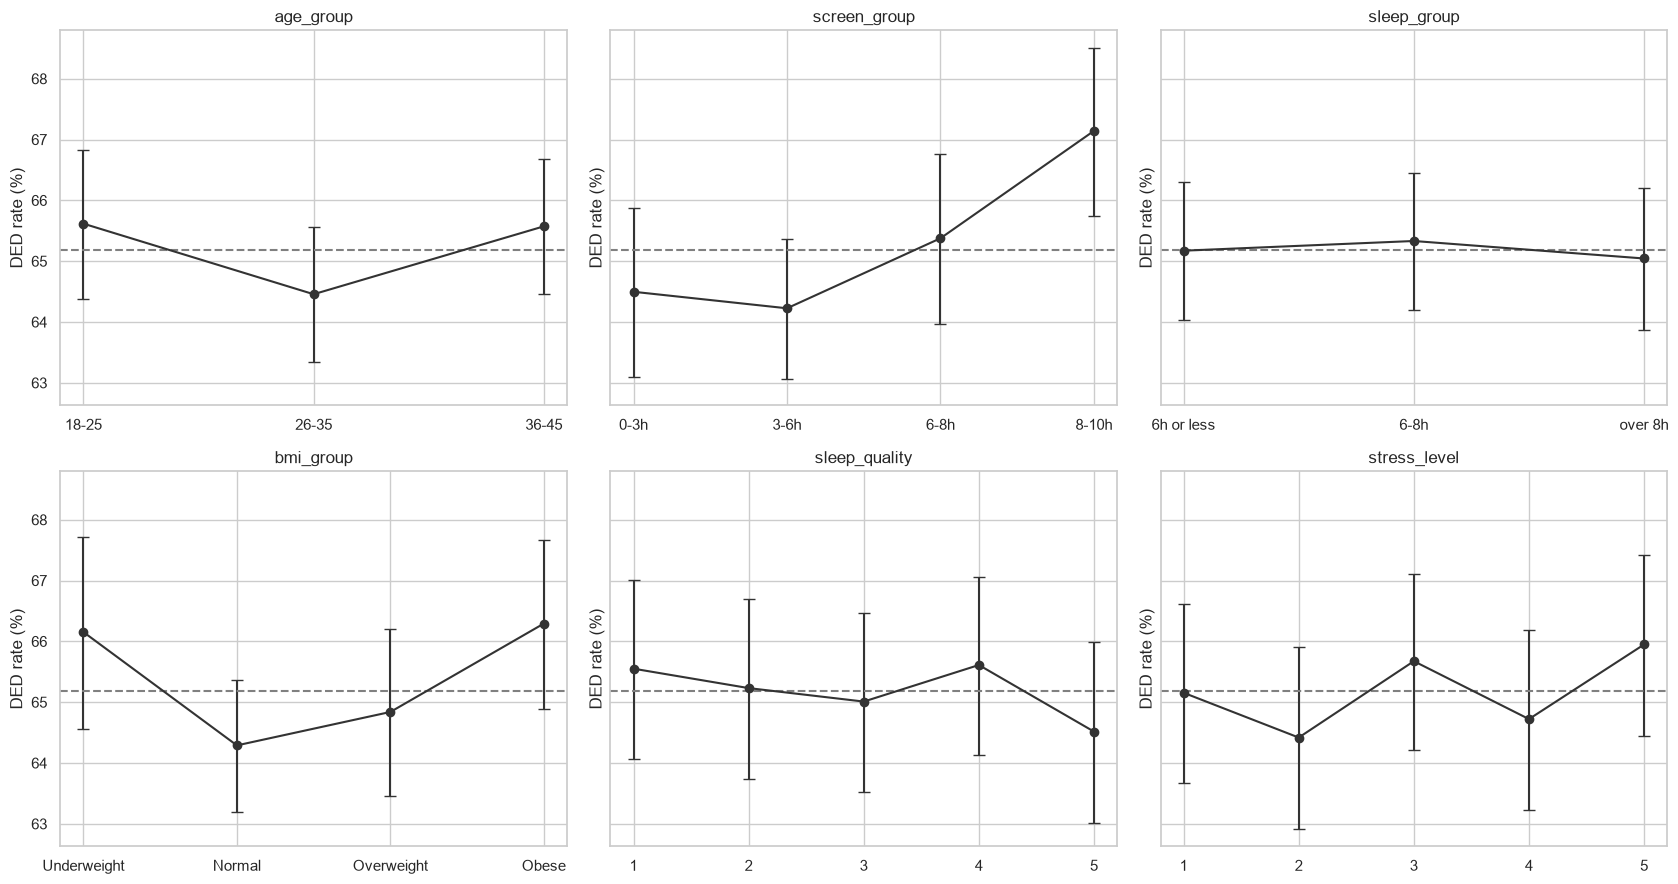

In [9]:
def rate_table(frame, col):
    g = frame.groupby(col, observed=True)[TARGET].agg(["sum", "count"])
    lo, hi = proportion_confint(g["sum"], g["count"], method="wilson")
    g["rate"] = g["sum"] / g["count"]; g["lo"] = lo; g["hi"] = hi
    return g

ordered = [c for c in ["age_group", "screen_group", "sleep_group", "bmi_group", "sleep_quality", "stress_level"] if c in df.columns]
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharey=True)
for ax, c in zip(axes.ravel(), ordered):
    g = rate_table(df, c)
    x = np.arange(len(g))
    ax.errorbar(x, g.rate * 100, yerr=[(g.rate - g.lo) * 100, (g.hi - g.rate) * 100], fmt="o-", color="#333", capsize=4)
    ax.axhline(prevalence * 100, ls="--", color="grey")
    ax.set_xticks(x); ax.set_xticklabels([str(i) for i in g.index]); ax.set_title(c); ax.set_ylabel("DED rate (%)")
plt.tight_layout(); plt.show()

### 3.4 Two factors at once: screen time and sleep
Each square shows the **DED rate (%)** for people with that mix of screen time and sleep. A pattern that grows toward one corner suggests the two factors add up.

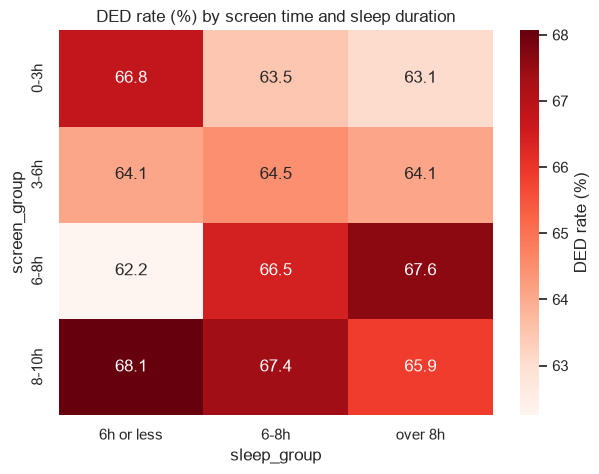

Smallest group size: 1386 people (very small groups give unreliable percentages).


In [10]:
pivot = df.pivot_table(values=TARGET, index="screen_group", columns="sleep_group", aggfunc="mean", observed=True) * 100
counts_p = df.pivot_table(values=TARGET, index="screen_group", columns="sleep_group", aggfunc="count", observed=True)
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "DED rate (%)"})
plt.title("DED rate (%) by screen time and sleep duration"); plt.show()
print("Smallest group size:", int(counts_p.min().min()), "people (very small groups give unreliable percentages).")

### 3.5 Risk ratios for every yes/no factor
A **risk ratio (RR)** compares the DED rate of people who have the factor with those who do not.
- **RR = 1** means no difference.
- **RR = 1.5** means 50% higher risk. **RR = 0.8** means 20% lower risk.

Lines that cross the dashed line at 1 are **not clearly different from no effect**. Red labels are eye symptoms (these are part of the picture of dry eye itself, not independent lifestyle factors).

,factor,rate_if_yes,rate_if_no,RR,lo,hi
0,smart_device_before_bed,0.646,0.658,0.981,0.961,1.001
1,smoking,0.649,0.654,0.993,0.973,1.013
2,ongoing_medication,0.650,0.654,0.994,0.974,1.014
3,medical_issue,0.651,0.652,0.998,0.978,1.019
4,wake_up_during_night,0.652,0.652,1.000,0.979,1.020
5,sleep_disorder,0.653,0.651,1.004,0.984,1.024
6,caffeine_consumption,0.653,0.650,1.004,0.984,1.025
7,feel_sleepy_during_day,0.654,0.650,1.007,0.987,1.028
8,blue_light_filter,0.654,0.649,1.007,0.987,1.028
9,high_bp,0.662,0.651,1.016,0.972,1.062


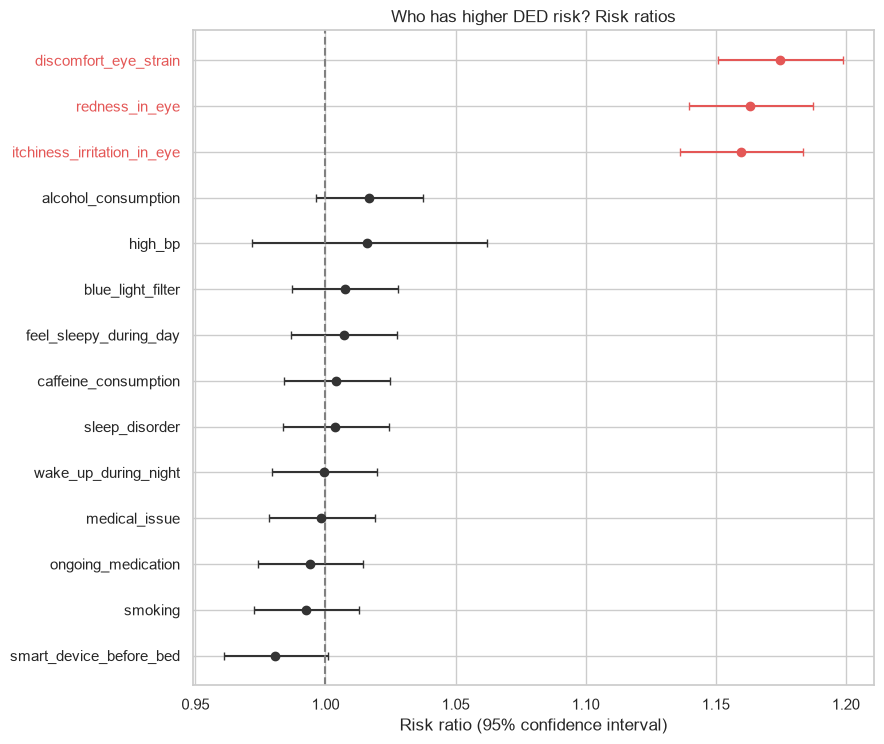

In [11]:
rows = []
for c in BIN_ALL:
    a, b = df.loc[df[c] == 1, TARGET], df.loc[df[c] == 0, TARGET]
    p1, p0, n1, n0 = a.mean(), b.mean(), len(a), len(b)
    if min(p1, p0) == 0 or min(n1, n0) == 0:
        continue
    rr = p1 / p0
    se = np.sqrt((1 - p1) / (n1 * p1) + (1 - p0) / (n0 * p0))
    rows.append({"factor": c, "rate_if_yes": p1, "rate_if_no": p0, "RR": rr,
                 "lo": np.exp(np.log(rr) - 1.96 * se), "hi": np.exp(np.log(rr) + 1.96 * se)})
rr_df = pd.DataFrame(rows).sort_values("RR").reset_index(drop=True)
display(rr_df.round(3))

fig, ax = plt.subplots(figsize=(9, 0.4 * len(rr_df) + 2))
for i, r in rr_df.iterrows():
    colr = "#E45756" if r.factor in SYMPTOMS else "#333"
    ax.errorbar(r.RR, i, xerr=[[r.RR - r.lo], [r.hi - r.RR]], fmt="o", color=colr, capsize=3)
ax.axvline(1, ls="--", color="grey")
ax.set_yticks(range(len(rr_df))); ax.set_yticklabels(rr_df.factor)
for lbl in ax.get_yticklabels():
    if lbl.get_text() in SYMPTOMS: lbl.set_color("#E45756")
ax.set_xlabel("Risk ratio (95% confidence interval)"); ax.set_title("Who has higher DED risk? Risk ratios")
plt.tight_layout(); plt.show()

### 3.6 How do the measurements relate to each other and to DED?
We use **Spearman correlation** (from -1 to +1). It works for scores like 1 to 5 and is not fooled by unusual values. Near 0 means no link.

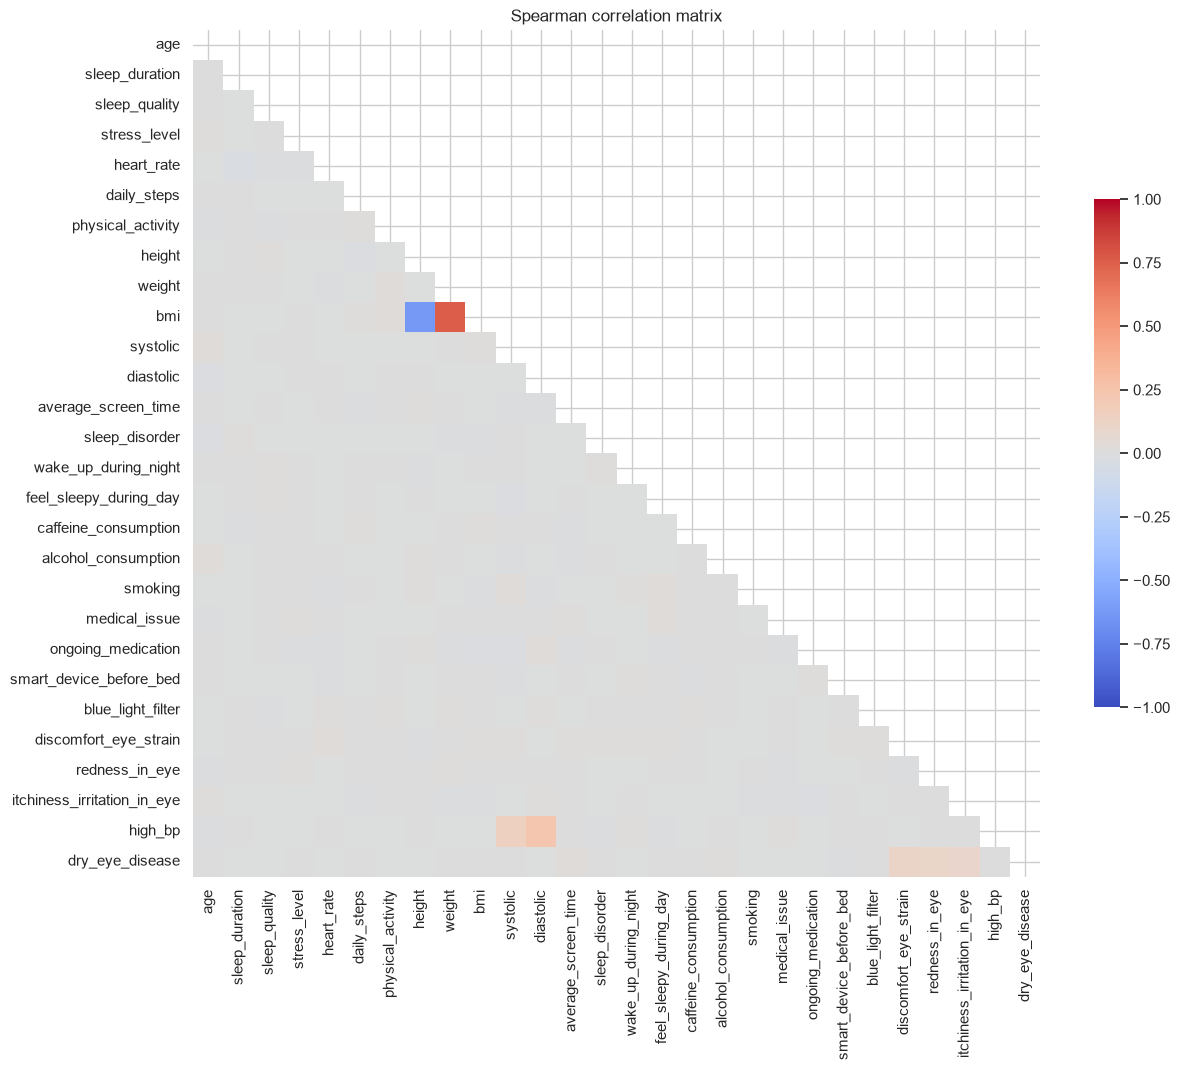

Strongest correlations with having DED:


,spearman_r
discomfort_eye_strain,0.110
redness_in_eye,0.103
itchiness_irritation_in_eye,0.101
average_screen_time,0.023
smart_device_before_bed,-0.013
alcohol_consumption,0.011
systolic,0.007
height,-0.006
daily_steps,0.006
stress_level,0.005


In [12]:
corr_cols = NUM_ALL + BIN_ALL + [TARGET]
corr = df[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.6})
plt.title("Spearman correlation matrix"); plt.show()

target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Strongest correlations with having DED:")
display(target_corr.head(10).round(3).to_frame("spearman_r"))

## Part 4: Statistical testing
A chart may show a difference that is just luck. Statistical tests tell us how likely the difference would be **if there were really no link**.

**Key ideas explained**
- **p-value:** the chance of seeing a difference this big by luck alone. Small (below 0.05) suggests a real link.
- **Multiple comparisons:** if you run 30 tests, a few will look "significant" by pure luck. We correct for this using the **Benjamini-Hochberg false discovery rate** and report the *adjusted* p-value.
- **Effect size:** how **big** the link is. With 20,000 people, even a tiny difference gets a very small p-value, so **a significant result is not automatically an important one**. We judge importance by effect size:

| Effect size | Negligible | Small | Medium | Large |
|---|---|---|---|---|
| Rank-biserial r, Cramer's V | below 0.1 | 0.1 to 0.3 | 0.3 to 0.5 | 0.5 or more |

**Tests used:** Mann-Whitney U for numbers (no bell-curve assumption); chi-square for yes/no factors; odds ratio with a 95% confidence interval for direction.

In [13]:
def effect_label(x):
    a = abs(x)
    return "negligible" if a < 0.1 else "small" if a < 0.3 else "medium" if a < 0.5 else "large"

# ---- numeric measurements: Mann-Whitney U ----
rows = []
for c in NUM_ALL:
    a, b = df.loc[df[TARGET] == 1, c], df.loc[df[TARGET] == 0, c]
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * U / (len(a) * len(b)) - 1          # rank-biserial effect size; positive = higher in DED
    rows.append({"variable": c, "kind": "numeric", "test": "Mann-Whitney U", "median_DED": a.median(), "median_no_DED": b.median(),
                 "p_value": p, "effect_size": r, "odds_ratio": np.nan, "or_low": np.nan, "or_high": np.nan})
num_tests = pd.DataFrame(rows)

# ---- yes/no and category factors: chi-square ----
rows = []
for c in BIN_ALL + ["gender"]:
    ct = pd.crosstab(df[c], df[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))     # Cramer's V
    orr = lo_or = hi_or = np.nan
    if ct.shape == (2, 2):
        a_, b_, c_, d_ = ct.values.ravel()                           # rows: factor level (0,1); columns: DED (0,1)
        if min(a_, b_, c_, d_) > 0:
            orr = (a_ * d_) / (b_ * c_)
            se = np.sqrt(1/a_ + 1/b_ + 1/c_ + 1/d_)
            lo_or, hi_or = np.exp(np.log(orr) - 1.96 * se), np.exp(np.log(orr) + 1.96 * se)
    rows.append({"variable": c, "kind": "yes/no" if ct.shape == (2, 2) else "category", "test": "Chi-square",
                 "median_DED": np.nan, "median_no_DED": np.nan, "p_value": p, "effect_size": v, "odds_ratio": orr,
                 "or_low": lo_or, "or_high": hi_or})
cat_tests = pd.DataFrame(rows)

evidence = pd.concat([num_tests, cat_tests], ignore_index=True)
evidence["p_adjusted"] = multipletests(evidence.p_value, method="fdr_bh")[1]
evidence["significant"] = evidence.p_adjusted < 0.05
evidence["strength"] = evidence.effect_size.apply(effect_label)
evidence["is_symptom"] = evidence.variable.isin(SYMPTOMS)
evidence = evidence.sort_values("effect_size", key=abs, ascending=False).reset_index(drop=True)
display(evidence[["variable", "kind", "test", "p_adjusted", "effect_size", "strength", "odds_ratio", "or_low", "or_high", "significant"]].round(4))

,variable,kind,test,p_adjusted,effect_size,strength,odds_ratio,or_low,or_high,significant
0,discomfort_eye_strain,yes/no,Chi-square,0.0000,0.1098,small,1.5901,1.4995,1.6861,True
1,redness_in_eye,yes/no,Chi-square,0.0000,0.1033,small,1.5477,1.4595,1.6412,True
2,itchiness_irritation_in_eye,yes/no,Chi-square,0.0000,0.1012,small,1.5335,1.4461,1.6261,True
3,average_screen_time,numeric,Mann-Whitney U,0.0101,0.0273,negligible,NaN,NaN,NaN,True
4,gender,yes/no,Chi-square,0.1222,0.0162,negligible,0.9338,0.8810,0.9897,False
5,smart_device_before_bed,yes/no,Chi-square,0.2876,0.0132,negligible,0.9456,0.8922,1.0023,False
6,alcohol_consumption,yes/no,Chi-square,0.4589,0.0112,negligible,1.0484,0.9891,1.1112,False
7,systolic,numeric,Mann-Whitney U,0.7574,0.0089,negligible,NaN,NaN,NaN,False
8,height,numeric,Mann-Whitney U,0.7574,-0.0078,negligible,NaN,NaN,NaN,False
9,daily_steps,numeric,Mann-Whitney U,0.7574,0.0068,negligible,NaN,NaN,NaN,False


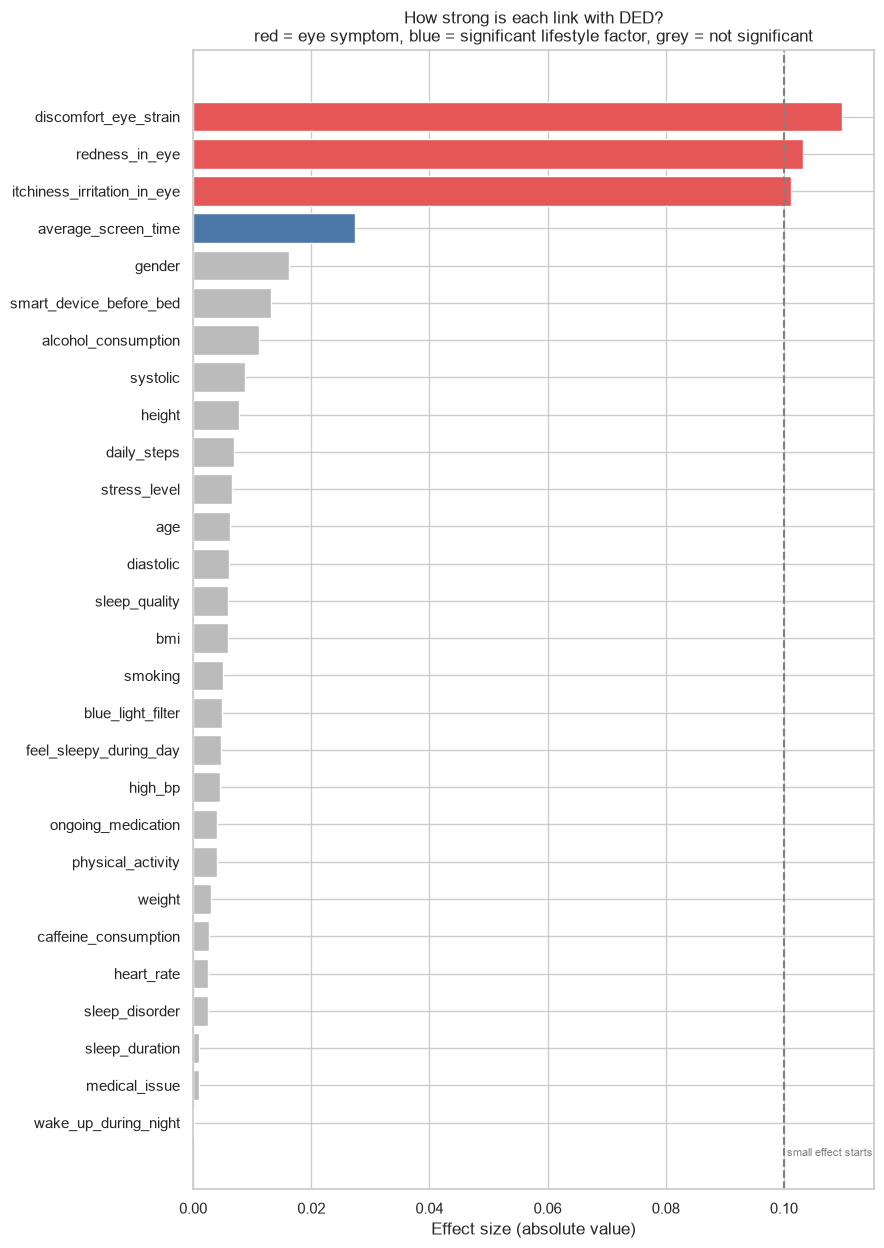

Links that are BOTH statistically significant AND at least small in size:
['discomfort_eye_strain', 'redness_in_eye', 'itchiness_irritation_in_eye']

Significant but negligible (real but too small to matter in practice):
['average_screen_time']


In [14]:
fig, ax = plt.subplots(figsize=(9, 0.38 * len(evidence) + 2))
colors = ["#E45756" if s else ("#4C78A8" if sig else "#BBBBBB") for s, sig in zip(evidence.is_symptom, evidence.significant)]
ax.barh(evidence.variable[::-1], evidence.effect_size.abs()[::-1], color=colors[::-1])
ax.axvline(0.1, ls="--", color="grey"); ax.text(0.1, -0.9, " small effect starts", color="grey", fontsize=8)
ax.set_xlabel("Effect size (absolute value)")
ax.set_title("How strong is each link with DED?\nred = eye symptom, blue = significant lifestyle factor, grey = not significant")
plt.tight_layout(); plt.show()

meaningful = evidence[(evidence.significant) & (evidence.effect_size.abs() >= 0.1)]
print("Links that are BOTH statistically significant AND at least small in size:")
print(meaningful.variable.tolist() or "None. No factor shows even a small effect.")
print("\nSignificant but negligible (real but too small to matter in practice):")
print(evidence[(evidence.significant) & (evidence.effect_size.abs() < 0.1)].variable.tolist() or "None")

### 4.2 A warning about the eye symptoms
Redness, itchiness and eye strain are **symptoms of dry eye**, so they are naturally linked to the diagnosis. If they are strongly linked to the target, then using them to "predict" DED is partly **circular**: the model is just reading the symptoms the diagnosis is built on, not learning something new.

That is why Part 6 builds **two separate models**:
- **Scenario A, lifestyle only:** can we estimate risk **before** symptoms appear? This is the useful screening question.
- **Scenario B, lifestyle + symptoms:** how much does the model improve when symptoms are included?

In [15]:
sym = evidence[evidence.is_symptom][["variable", "p_adjusted", "effect_size", "strength", "odds_ratio", "or_low", "or_high"]]
display(sym.round(4))
if len(sym) and sym.effect_size.abs().max() >= 0.3:
    print("At least one symptom is strongly tied to the diagnosis: Scenario B will likely look much better than Scenario A.")
else:
    print("The symptoms are not strongly tied to the diagnosis in this dataset. That is unusual for real patients and is another sign to treat this data carefully.")

,variable,p_adjusted,effect_size,strength,odds_ratio,or_low,or_high
0,discomfort_eye_strain,0.0,0.1098,small,1.5901,1.4995,1.6861
1,redness_in_eye,0.0,0.1033,small,1.5477,1.4595,1.6412
2,itchiness_irritation_in_eye,0.0,0.1012,small,1.5335,1.4461,1.6261


The symptoms are not strongly tied to the diagnosis in this dataset. That is unusual for real patients and is another sign to treat this data carefully.


## Part 5: Multivariable regression (adjusting for everything at once)
A single test looks at one factor at a time, but factors overlap (people who sleep badly may also be more stressed). **Logistic regression** estimates each factor's link with DED **while holding the others fixed**.

How to read the result: the **odds ratio (OR)** works like the risk ratio.
- OR above 1 means higher odds of DED. Below 1 means lower. Exactly 1 means no link.
- Measurements are **standardised** (converted to "per 1 standard deviation") so their ORs can be compared fairly.
- **VIF** checks whether factors repeat each other. Above 5 is a concern.

Eye symptoms are **excluded** here, since they are part of the condition.

In [16]:
Xlr = df[NUM_ML + BIN_LIFESTYLE].copy()
Xlr[NUM_ML] = (Xlr[NUM_ML] - Xlr[NUM_ML].mean()) / Xlr[NUM_ML].std()          # per 1 standard deviation
Xlr = pd.concat([Xlr, pd.get_dummies(df["gender"], prefix="gender", drop_first=True).astype(int)], axis=1)
Xc = sm.add_constant(Xlr.astype(float))
logit = sm.Logit(df[TARGET], Xc).fit(disp=0)

res = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(logit.conf_int()[0]),
                    "ci_high": np.exp(logit.conf_int()[1]), "p_value": logit.pvalues}).drop("const")
res["p_adjusted"] = multipletests(res.p_value, method="fdr_bh")[1]
res = res.sort_values("p_value")
display(res.round(4))
print(f"Whole-model test (is the model better than knowing nothing?): p = {logit.llr_pvalue:.4g}")
print(f"Pseudo R-squared = {logit.prsquared:.4f}  (0 = explains nothing, 1 = explains everything; real-world values of 0.1 to 0.3 are already good)")

vif = pd.DataFrame({"feature": Xc.columns, "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
vif = vif[vif.feature != "const"].sort_values("VIF", ascending=False)
print("\nHighest VIF values (above 5 would be a concern):")
display(vif.head(5).round(2))

,odds_ratio,ci_low,ci_high,p_value,p_adjusted
average_screen_time,1.0484,1.0183,1.0794,0.0015,0.0342
gender_M,0.9356,0.8826,0.9917,0.0251,0.2890
smart_device_before_bed,0.9446,0.8911,1.0012,0.0550,0.4217
alcohol_consumption,1.0502,0.9907,1.1132,0.0995,0.5723
bmi,1.0149,0.9857,1.0449,0.3210,0.7716
systolic,1.0140,0.9846,1.0444,0.3544,0.7716
diastolic,0.9874,0.9582,1.0175,0.4079,0.7716
daily_steps,1.0122,0.9831,1.0421,0.4146,0.7716
sleep_quality,0.9887,0.9603,1.0180,0.4458,0.7716
smoking,0.9780,0.9227,1.0367,0.4552,0.7716


Whole-model test (is the model better than knowing nothing?): p = 0.1682
Pseudo R-squared = 0.0011  (0 = explains nothing, 1 = explains everything; real-world values of 0.1 to 0.3 are already good)



Highest VIF values (above 5 would be a concern):


,feature,VIF
22,high_bp,1.09
10,diastolic,1.06
9,systolic,1.03
1,age,1.00
19,ongoing_medication,1.00


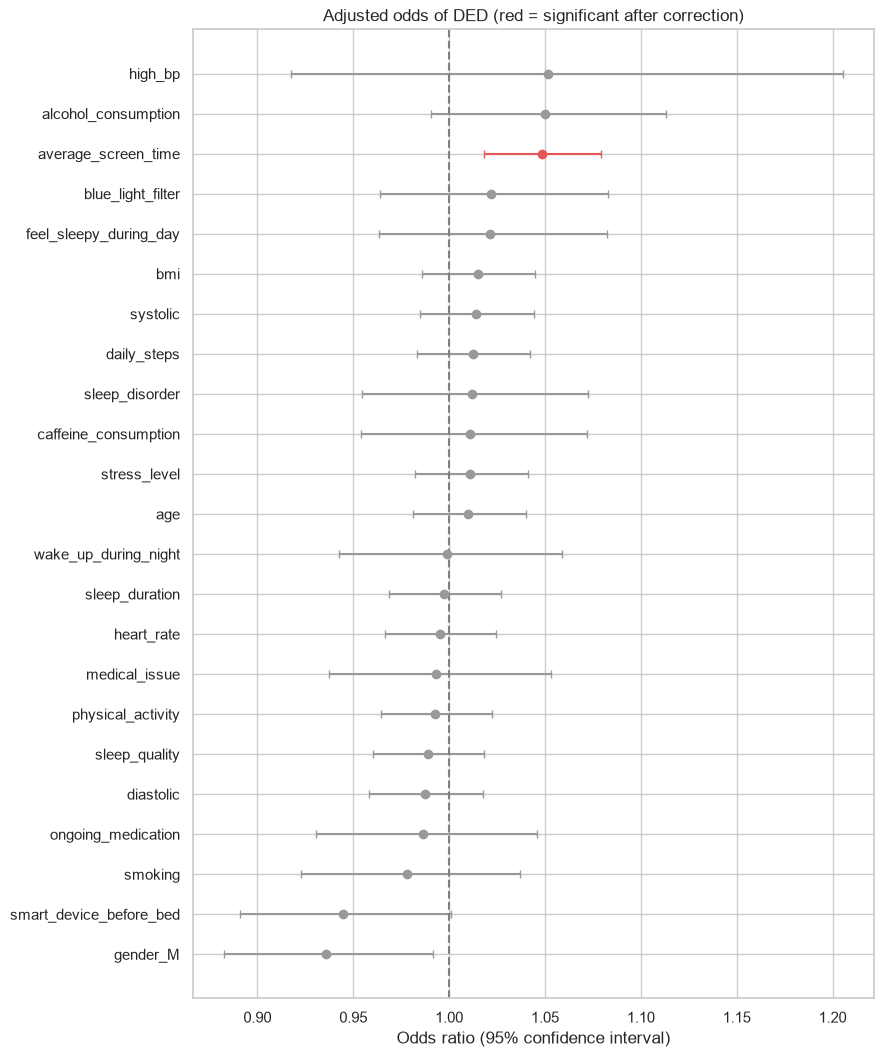

In [17]:
plot_res = res.sort_values("odds_ratio").reset_index()
fig, ax = plt.subplots(figsize=(9, 0.38 * len(plot_res) + 2))
for i, r in plot_res.iterrows():
    sig = r.p_adjusted < 0.05
    ax.errorbar(r.odds_ratio, i, xerr=[[r.odds_ratio - r.ci_low], [r.ci_high - r.odds_ratio]], fmt="o",
                color="#E45756" if sig else "#999999", capsize=3)
ax.axvline(1, ls="--", color="grey")
ax.set_yticks(range(len(plot_res))); ax.set_yticklabels(plot_res["index"])
ax.set_xlabel("Odds ratio (95% confidence interval)"); ax.set_title("Adjusted odds of DED (red = significant after correction)")
plt.tight_layout(); plt.show()

## Part 6: Machine learning
Now we ask a predictive question: **given a person's lifestyle information, can a model estimate whether they have DED?**

### How we keep the evaluation honest
| Step | What we do | Why |
|---|---|---|
| Split | 80% **train**, 20% **test**, same DED share in both (stratified) | The test set simulates new patients |
| Baseline | A model that guesses the most common answer | Any real model must beat this |
| Cross-validation | 5 rounds on the training data only | Shows if the score is stable, not lucky |
| Tuning | Small random search, training data only | Finds good settings without touching the test set |
| Final test | The test set is used **once**, at the end | Prevents fooling ourselves |
| Confidence intervals | Bootstrapping on the test results | Shows how uncertain the score is |

### Metrics explained
- **AUC:** how well the model ranks sick above healthy. 0.5 is a coin flip, 1.0 is perfect.
- **Accuracy:** share of correct answers. Misleading if one group is much bigger.
- **Sensitivity (recall):** of people who truly have DED, how many did we catch?
- **Specificity:** of people without DED, how many did we correctly clear?
- **Precision:** when the model says "DED", how often is it right?
- **F1:** a balance of precision and sensitivity.

In [18]:
ALL_FEATURES = NUM_ML + ["gender"] + BIN_ALL
X_all, y_all = df[ALL_FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
print(f"Training people: {len(X_train):,} (DED {y_train.mean():.1%}) | Test people: {len(X_test):,} (DED {y_test.mean():.1%})")

SCENARIOS = {
    "A: Lifestyle only": NUM_ML + ["gender"] + BIN_LIFESTYLE,
    "B: Lifestyle + eye symptoms": NUM_ML + ["gender"] + BIN_LIFESTYLE + SYMPTOMS,
}
for k, v in SCENARIOS.items():
    print(f"{k}: {len(v)} input features")

Training people: 16,000 (DED 65.2%) | Test people: 4,000 (DED 65.2%)
A: Lifestyle only: 23 input features
B: Lifestyle + eye symptoms: 26 input features


In [20]:
def build_pipe(features, model):
    num = [c for c in features if c in NUM_ML]
    binc = [c for c in features if c in BIN_ALL]
    pre = ColumnTransformer([
        ("num", StandardScaler(), num),                                                          # put numbers on the same scale
        ("cat", OneHotEncoder(drop="if_binary", sparse_output=False, handle_unknown="ignore"), ["gender"]),
        ("bin", "passthrough", binc),                                                            # yes/no columns are already 0/1
    ], sparse_threshold=0)
    return Pipeline([("pre", pre), ("clf", model)])

def make_models():
    return {
        "Baseline (always most common)": DummyClassifier(strategy="prior"),
        "Logistic regression": LogisticRegression(max_iter=2000),
        "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, n_jobs=1, random_state=SEED),
        "Gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=150, random_state=SEED),
    }

GRIDS = {
    "Logistic regression": {"clf__C": [0.01, 0.1, 1, 10]},
    "Random forest": {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [5, 20, 50], "clf__max_features": ["sqrt", 0.5]},
    "Gradient boosting": {"clf__learning_rate": [0.03, 0.05, 0.1], "clf__max_depth": [2, 3, 5],
                          "clf__max_iter": [100, 200], "clf__l2_regularization": [0, 1, 5]},
}
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "accuracy": "accuracy", "bal_acc": "balanced_accuracy", "f1": "f1"}

def metrics_at(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"threshold": thr, "accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "sensitivity": tp / (tp + fn) if tp + fn else np.nan, "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "precision": tp / (tp + fp) if tp + fp else np.nan, "f1": f1_score(y, pred, zero_division=0),
            "auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p)}

def bootstrap_ci(y, p, fn, n=500):
    rng = np.random.default_rng(SEED); y = np.asarray(y); p = np.asarray(p); vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2: continue
        vals.append(fn(y[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])

In [21]:
def evaluate_scenario(name, features):
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
    # 1) Cross-validate every model on the TRAINING data only
    rows, auc_means = [], {}
    for mname, m in make_models().items():
        s = cross_validate(build_pipe(features, m), X_train[features], y_train, cv=skf, scoring=SCORING, n_jobs=-1)
        row = {"model": mname}
        for k in SCORING:
            row[k] = f"{s['test_' + k].mean():.3f} ± {s['test_' + k].std():.3f}"
        rows.append(row); auc_means[mname] = s["test_roc_auc"].mean()
    cv_table = pd.DataFrame(rows).set_index("model")

    # 2) Tune the best real model (training data only)
    best_name = max((k for k in auc_means if not k.startswith("Baseline")), key=auc_means.get)
    search = RandomizedSearchCV(build_pipe(features, make_models()[best_name]), GRIDS[best_name], n_iter=8, cv=3,
                                scoring="roc_auc", random_state=SEED, n_jobs=-1)
    search.fit(X_train[features], y_train)
    final = search.best_estimator_

    # 3) Choose the decision threshold on out-of-fold training predictions (Youden's J: best sensitivity + specificity balance)
    oof = cross_val_predict(final, X_train[features], y_train, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
    fpr, tpr, thr = roc_curve(y_train, oof)
    thr_best = float(thr[np.argmax(tpr - fpr)])

    # 4) Open the locked test set ONCE
    p_test = final.predict_proba(X_test[features])[:, 1]
    out = {"name": name, "features": features, "cv_table": cv_table, "best_name": best_name, "best_params": search.best_params_,
           "model": final, "thr": thr_best, "p_test": p_test, "test_default": metrics_at(y_test, p_test, 0.5),
           "test_tuned": metrics_at(y_test, p_test, thr_best),
           "auc_ci": bootstrap_ci(y_test, p_test, roc_auc_score),
           "baseline_acc": max(y_test.mean(), 1 - y_test.mean())}
    return out

results = {}
for name, feats in SCENARIOS.items():
    print("Running", name, "...")
    results[name] = evaluate_scenario(name, feats)
print("Done.")

Running A: Lifestyle only ...


Running B: Lifestyle + eye symptoms ...


Done.


### 6.1 Cross-validation results (training data only)
Each cell shows the **average ± variation across 5 rounds**. A model is only worth using if it clearly beats the baseline row.

In [24]:
for name, r in results.items():
    print(f"\n=== Scenario {name} ===")
    display(r["cv_table"])
    print("Best model:", r["best_name"], "| tuned settings:", r["best_params"])


=== Scenario A: Lifestyle only ===


,roc_auc,pr_auc,accuracy,bal_acc,f1
model,,,,,
Baseline (always most common),0.500 ± 0.000,0.652 ± 0.000,0.652 ± 0.000,0.500 ± 0.000,0.789 ± 0.000
Logistic regression,0.505 ± 0.004,0.661 ± 0.004,0.652 ± 0.000,0.500 ± 0.000,0.789 ± 0.000
Random forest,0.504 ± 0.004,0.661 ± 0.003,0.652 ± 0.000,0.500 ± 0.000,0.789 ± 0.000
Gradient boosting,0.508 ± 0.004,0.665 ± 0.005,0.652 ± 0.000,0.500 ± 0.000,0.789 ± 0.000


Best model: Gradient boosting | tuned settings: {'clf__max_iter': 200, 'clf__max_depth': 2, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 5}

=== Scenario B: Lifestyle + eye symptoms ===


,roc_auc,pr_auc,accuracy,bal_acc,f1
model,,,,,
Baseline (always most common),0.500 ± 0.000,0.652 ± 0.000,0.652 ± 0.000,0.500 ± 0.000,0.789 ± 0.000
Logistic regression,0.598 ± 0.010,0.703 ± 0.006,0.677 ± 0.004,0.553 ± 0.006,0.796 ± 0.002
Random forest,0.593 ± 0.009,0.701 ± 0.006,0.696 ± 0.006,0.591 ± 0.007,0.801 ± 0.004
Gradient boosting,0.594 ± 0.008,0.703 ± 0.007,0.697 ± 0.007,0.592 ± 0.008,0.802 ± 0.005


Best model: Logistic regression | tuned settings: {'clf__C': 1}


### 6.2 Final results on the locked test set
**AUC 95% range** is from bootstrapping. If the range **includes 0.5**, the model is **not clearly better than a coin flip**.

*Note:* the chosen threshold balances sensitivity and specificity, so its **accuracy can sit below the baseline accuracy**. That is not a bug: accuracy rewards always guessing the bigger group, while AUC and sensitivity/specificity measure real discrimination.

In [25]:
rows = []
for name, r in results.items():
    t = r["test_tuned"]
    rows.append({"scenario": name, "model": r["best_name"], "AUC": round(t["auc"], 3),
                 "AUC 95% range": f"{r['auc_ci'][0]:.3f} to {r['auc_ci'][1]:.3f}", "PR-AUC": round(t["pr_auc"], 3),
                 "accuracy": round(t["accuracy"], 3), "baseline accuracy": round(r["baseline_acc"], 3),
                 "sensitivity": round(t["sensitivity"], 3), "specificity": round(t["specificity"], 3),
                 "precision": round(t["precision"], 3), "F1": round(t["f1"], 3), "threshold": round(t["threshold"], 3)})
summary_table = pd.DataFrame(rows).set_index("scenario")
display(summary_table.T)

for name, r in results.items():
    lo, hi = r["auc_ci"]
    verdict = ("clearly better than chance" if lo > 0.5 else "NOT clearly better than chance")
    print(f"{name}: AUC {r['test_tuned']['auc']:.3f} (95% range {lo:.3f} to {hi:.3f}), {verdict}.")

scenario,A: Lifestyle only,B: Lifestyle + eye symptoms
model,Gradient boosting,Logistic regression
AUC,0.514,0.606
AUC 95% range,0.496 to 0.531,0.587 to 0.624
PR-AUC,0.667,0.706
accuracy,0.419,0.69
baseline accuracy,0.652,0.652
sensitivity,0.228,0.909
specificity,0.777,0.279
precision,0.656,0.702
F1,0.338,0.793


A: Lifestyle only: AUC 0.514 (95% range 0.496 to 0.531), NOT clearly better than chance.
B: Lifestyle + eye symptoms: AUC 0.606 (95% range 0.587 to 0.624), clearly better than chance.


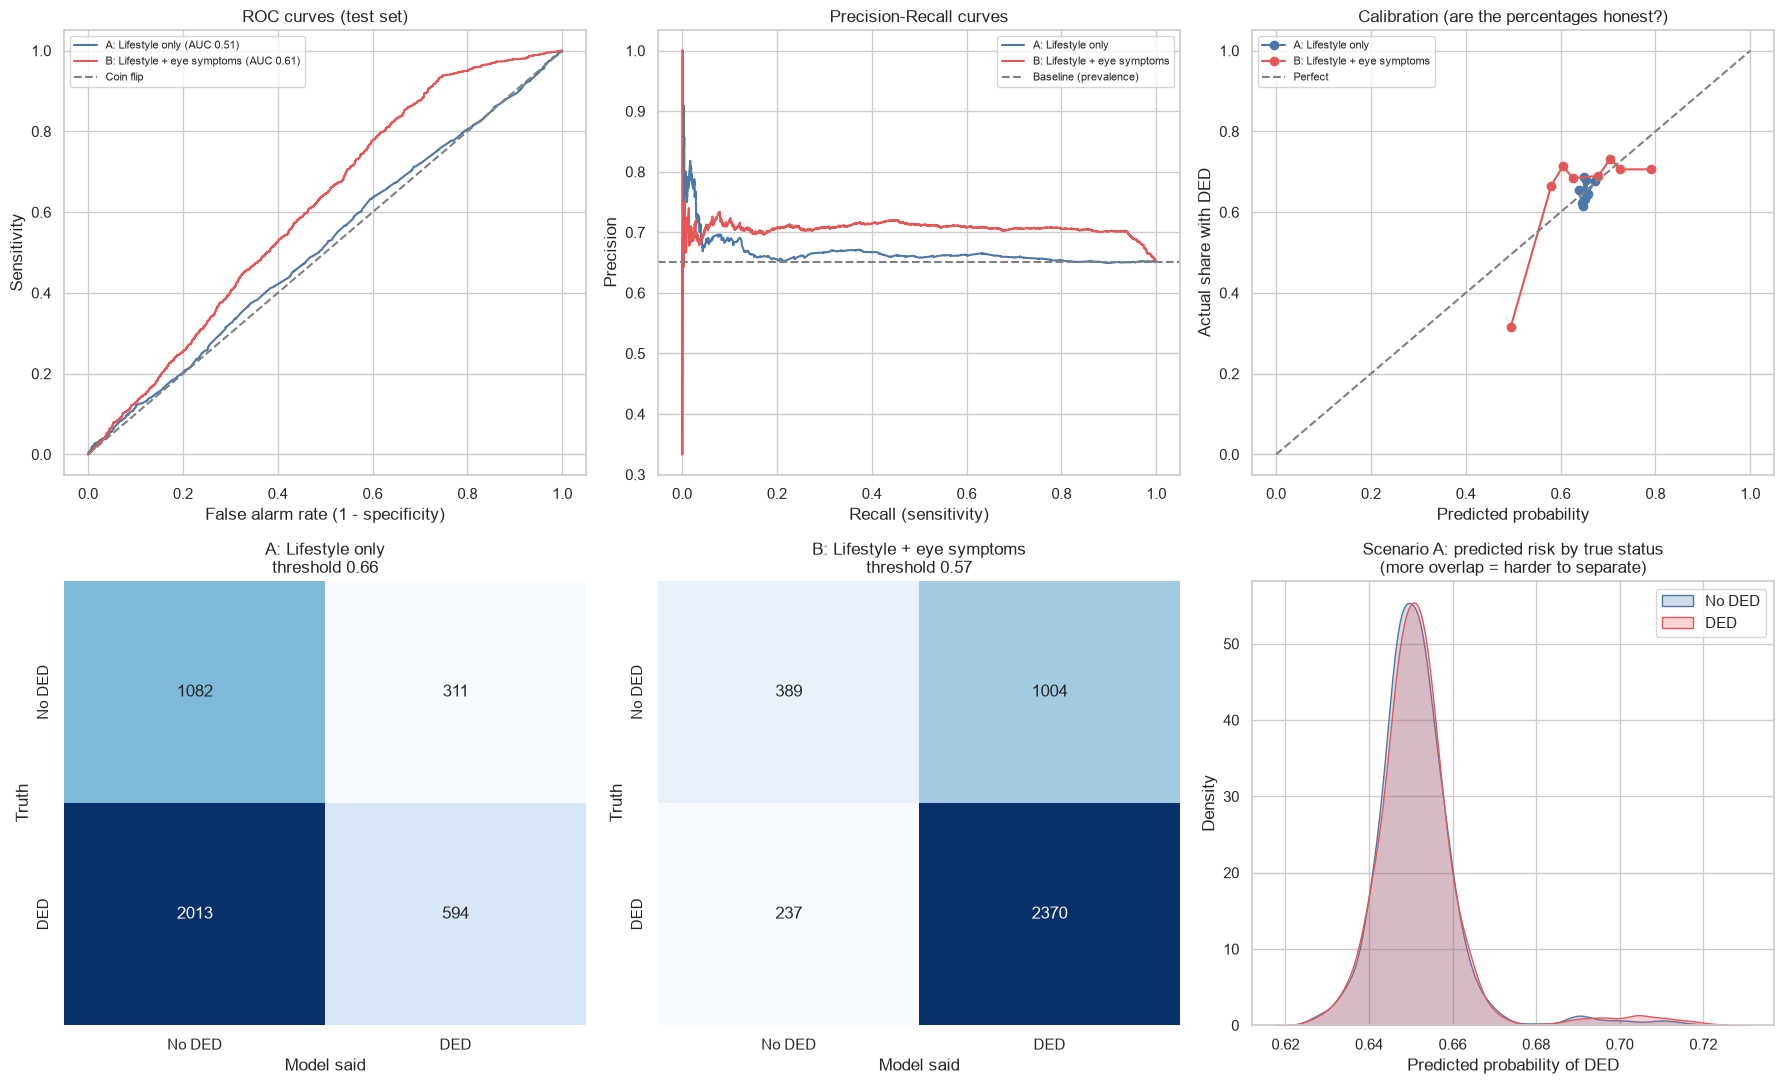

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
palette = ["#4C78A8", "#E45756"]

# ROC curves
ax = axes[0, 0]
for (name, r), col in zip(results.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, r["p_test"])
    ax.plot(fpr, tpr, color=col, label=f"{name} (AUC {r['test_tuned']['auc']:.2f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Coin flip"); ax.set_xlabel("False alarm rate (1 - specificity)")
ax.set_ylabel("Sensitivity"); ax.set_title("ROC curves (test set)"); ax.legend(fontsize=8)

# Precision-Recall curves
ax = axes[0, 1]
for (name, r), col in zip(results.items(), palette):
    pr, rc, _ = precision_recall_curve(y_test, r["p_test"])
    ax.plot(rc, pr, color=col, label=name)
ax.axhline(y_test.mean(), ls="--", color="grey", label="Baseline (prevalence)")
ax.set_xlabel("Recall (sensitivity)"); ax.set_ylabel("Precision"); ax.set_title("Precision-Recall curves"); ax.legend(fontsize=8)

# Calibration
ax = axes[0, 2]
for (name, r), col in zip(results.items(), palette):
    fp, mp = calibration_curve(y_test, r["p_test"], n_bins=8, strategy="quantile")
    ax.plot(mp, fp, "o-", color=col, label=name)
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect"); ax.set_xlabel("Predicted probability")
ax.set_ylabel("Actual share with DED"); ax.set_title("Calibration (are the percentages honest?)"); ax.legend(fontsize=8)

# Confusion matrices
for ax, (name, r) in zip(axes[1, :2], results.items()):
    pred = (r["p_test"] >= r["thr"]).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No DED", "DED"], yticklabels=["No DED", "DED"])
    ax.set_title(f"{name}\nthreshold {r['thr']:.2f}"); ax.set_xlabel("Model said"); ax.set_ylabel("Truth")

# Distribution of predicted risk
ax = axes[1, 2]
r = results["A: Lifestyle only"]
sns.kdeplot(x=r["p_test"][y_test.values == 0], fill=True, color=COLORS[0], label="No DED", ax=ax)
sns.kdeplot(x=r["p_test"][y_test.values == 1], fill=True, color=COLORS[1], label="DED", ax=ax)
ax.set_title("Scenario A: predicted risk by true status\n(more overlap = harder to separate)"); ax.set_xlabel("Predicted probability of DED"); ax.legend()
plt.tight_layout(); plt.show()

### 6.3 Choosing the decision threshold
The model outputs a **probability**. "Say DED if probability is at least 0.5" is arbitrary. Moving the threshold trades **sensitivity** against **specificity**. A screening programme usually prefers catching more people (higher sensitivity) even if that means more false alarms. **The clinic, not the data scientist, should choose the balance.**

In [27]:
r = results["A: Lifestyle only"]
rows = []
for t in sorted(set([0.3, 0.4, 0.5, 0.6, 0.7] + [round(r["thr"], 3)])):
    m = metrics_at(y_test, r["p_test"], t)
    rows.append({"threshold": t, "sensitivity": m["sensitivity"], "specificity": m["specificity"], "precision": m["precision"], "accuracy": m["accuracy"],
                 "flagged_as_DED_%": float((r["p_test"] >= t).mean() * 100)})
display(pd.DataFrame(rows).round(3).set_index("threshold"))
print(f"Threshold {r['thr']:.3f} was chosen on training data (best balance of sensitivity and specificity).")

,sensitivity,specificity,precision,accuracy,flagged_as_DED_%
threshold,,,,,
0.300,1.000,0.000,0.652,0.652,100.000
0.400,1.000,0.000,0.652,0.652,100.000
0.500,1.000,0.000,0.652,0.652,100.000
0.600,1.000,0.000,0.652,0.652,100.000
0.656,0.218,0.783,0.653,0.415,21.775
0.700,0.020,0.990,0.788,0.358,1.650


Threshold 0.656 was chosen on training data (best balance of sensitivity and specificity).


## Part 7: Explainability: what is the model actually using?
**Permutation importance** shuffles one input at a time and measures how much the model's AUC drops. A big drop means the model relies on that input. If shuffling barely changes anything, the input is not useful. This is more trustworthy than the built-in "feature importance" of tree models, which can favour inputs with many distinct values.

The bars show the average drop with its variation across 10 shuffles.

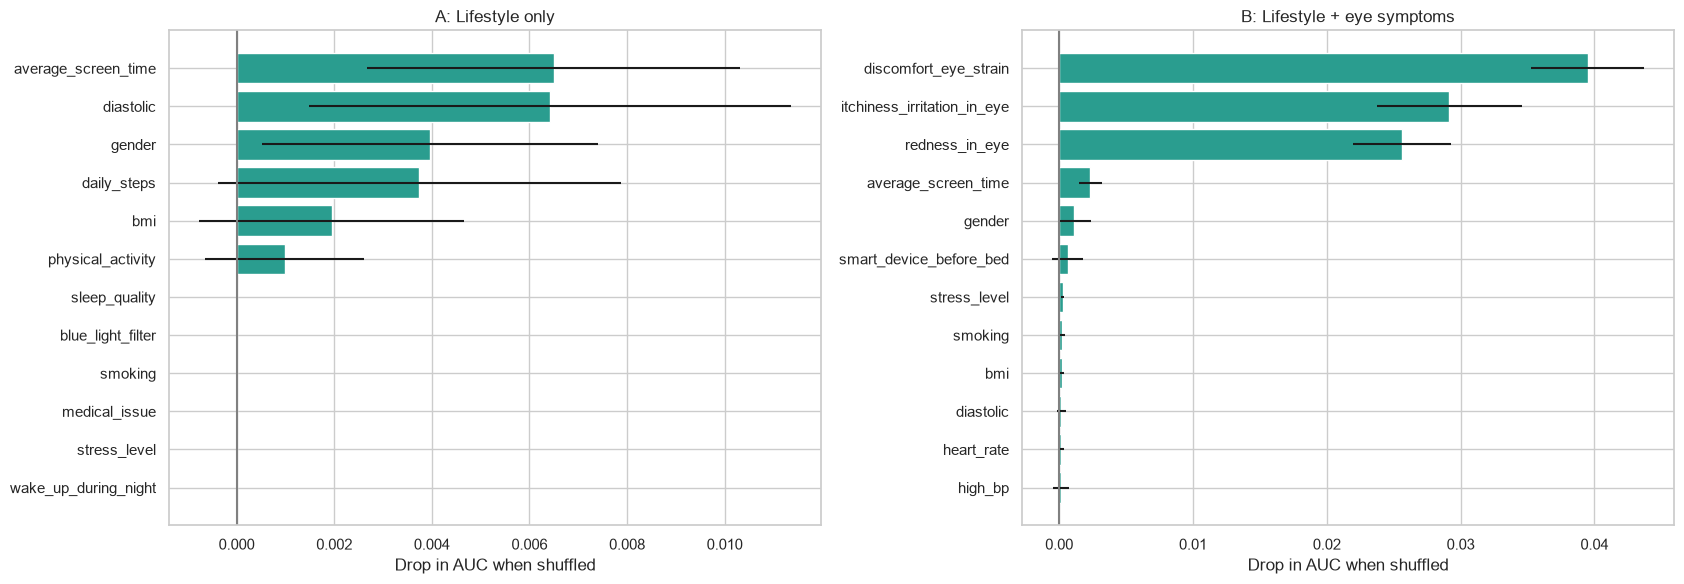

,feature,importance,std
10,average_screen_time,0.0065,0.0038
9,diastolic,0.0064,0.0049
11,gender,0.0040,0.0034
5,daily_steps,0.0037,0.0041
7,bmi,0.0019,0.0027
6,physical_activity,0.0010,0.0016
2,sleep_quality,0.0000,0.0000
21,blue_light_filter,0.0000,0.0000


In [28]:
perm_tables = {}
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, (name, r) in zip(axes, results.items()):
    feats = r["features"]
    pi = permutation_importance(r["model"], X_test[feats], y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
    t = pd.DataFrame({"feature": feats, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)
    perm_tables[name] = t
    top = t.head(12).iloc[::-1]
    ax.barh(top.feature, top.importance, xerr=top["std"], color="#2A9D8F")
    ax.axvline(0, color="grey"); ax.set_title(f"{name}"); ax.set_xlabel("Drop in AUC when shuffled")
plt.tight_layout(); plt.show()
display(perm_tables["A: Lifestyle only"].head(8).round(4))

### 7.1 How does risk change with the top factors? (partial dependence)
A **partial dependence plot** shows the model's average predicted risk as one factor changes, with everything else kept as is. A flat line means the factor barely moves the prediction.

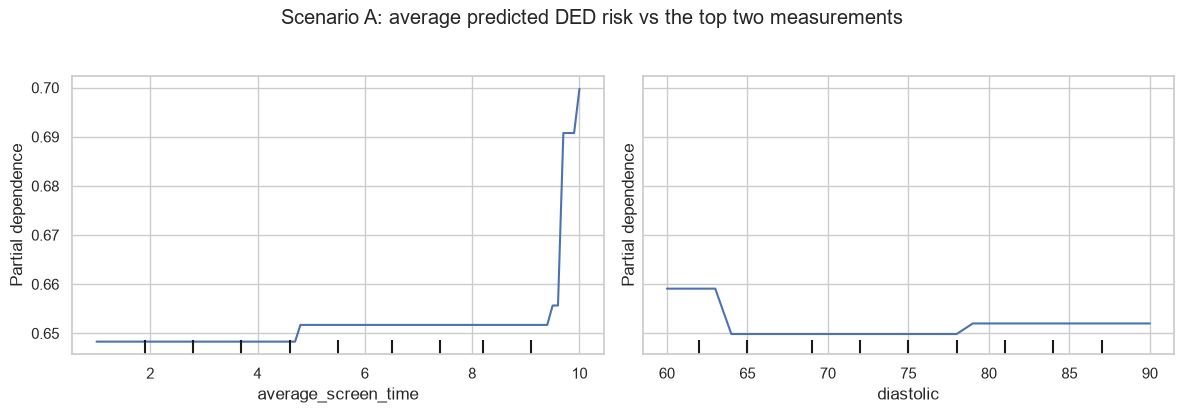

In [29]:
rA = results["A: Lifestyle only"]
top_numeric = [f for f in perm_tables["A: Lifestyle only"].feature if f in NUM_ML][:2]
try:
    fig, ax = plt.subplots(1, len(top_numeric), figsize=(6 * len(top_numeric), 4), sharey=True)
    PartialDependenceDisplay.from_estimator(rA["model"], X_test[rA["features"]], top_numeric, ax=np.atleast_1d(ax), kind="average")
    plt.suptitle("Scenario A: average predicted DED risk vs the top two measurements", y=1.03); plt.tight_layout(); plt.show()
except Exception as e:
    print("Partial dependence plot skipped:", e)

## Part 8: Subgroup (fairness) check
A model can look fine overall yet work worse for some groups. We check Scenario A's test results by **gender** and **age group**. Groups with fewer than 100 people give unreliable numbers, so they are flagged.

In [30]:
test_info = df.loc[X_test.index, ["gender", "age_group"]].copy()
test_info["y"] = y_test.values
test_info["p"] = rA["p_test"]
rows = []
for col in ["gender", "age_group"]:
    for level, g in test_info.groupby(col, observed=True):
        m = metrics_at(g.y, g.p, rA["thr"]) if g.y.nunique() == 2 else {}
        rows.append({"group": f"{col} = {level}", "n": len(g), "DED_rate": g.y.mean(), "AUC": m.get("auc", np.nan),
                     "sensitivity": m.get("sensitivity", np.nan), "specificity": m.get("specificity", np.nan),
                     "reliable (n >= 100)": len(g) >= 100})
display(pd.DataFrame(rows).round(3).set_index("group"))
print("Large gaps in AUC, sensitivity or specificity between groups would mean the model is not equally fair to everyone.")

,n,DED_rate,AUC,sensitivity,specificity,reliable (n >= 100)
group,,,,,,
gender = F,2012,0.659,0.511,0.272,0.719,True
gender = M,1988,0.645,0.512,0.182,0.833,True
age_group = 18-25,1164,0.658,0.496,0.174,0.822,True
age_group = 26-35,1432,0.649,0.544,0.162,0.831,True
age_group = 36-45,1404,0.649,0.504,0.340,0.686,True


Large gaps in AUC, sensitivity or specificity between groups would mean the model is not equally fair to everyone.


## Part 9: Summary, limitations and recommendations
### 9.1 Automatic summary of this run
The next cell writes the key numbers from your own results, so the summary always matches the analysis.

In [31]:
A_, B_ = results["A: Lifestyle only"], results["B: Lifestyle + eye symptoms"]
top_assoc = evidence[~evidence.is_symptom].head(3)
print(f"1. PREVALENCE: {prevalence:.1%} of the {n_total:,} people have dry eye disease.")
print(f"2. STRONGEST LIFESTYLE LINKS (by effect size): " + "; ".join(f"{r.variable} ({r.strength}, effect {r.effect_size:+.3f}, adj. p {r.p_adjusted:.3g})" for r in top_assoc.itertuples()))
print(f"3. PRACTICALLY MEANINGFUL LIFESTYLE LINKS: {meaningful[~meaningful.is_symptom].variable.tolist() or 'none (no factor reaches even a small effect)'}")
print(f"4. LIFESTYLE-ONLY MODEL ({A_['best_name']}): AUC {A_['test_tuned']['auc']:.3f} (95% range {A_['auc_ci'][0]:.3f} to {A_['auc_ci'][1]:.3f}); "
      f"accuracy {A_['test_tuned']['accuracy']:.1%} vs baseline {A_['baseline_acc']:.1%}.")
print(f"5. WITH SYMPTOMS ({B_['best_name']}): AUC {B_['test_tuned']['auc']:.3f} (95% range {B_['auc_ci'][0]:.3f} to {B_['auc_ci'][1]:.3f}); "
      f"improvement over lifestyle only: {B_['test_tuned']['auc'] - A_['test_tuned']['auc']:+.3f} AUC.")
if A_["auc_ci"][0] <= 0.5:
    print("\nINTERPRETATION: lifestyle information alone does NOT predict DED better than chance in this dataset. "
          "That is a valid scientific finding: it warns against building screening tools on these variables alone.")
elif A_["test_tuned"]["auc"] < 0.7:
    print("\nINTERPRETATION: lifestyle information carries a weak but real signal. It is not strong enough to diagnose or screen alone.")
else:
    print("\nINTERPRETATION: lifestyle information carries a useful signal for risk estimation. It still needs validation on real clinic data.")

1. PREVALENCE: 65.2% of the 20,000 people have dry eye disease.
2. STRONGEST LIFESTYLE LINKS (by effect size): average_screen_time (negligible, effect +0.027, adj. p 0.0101); gender (negligible, effect +0.016, adj. p 0.122); smart_device_before_bed (negligible, effect +0.013, adj. p 0.288)
3. PRACTICALLY MEANINGFUL LIFESTYLE LINKS: none (no factor reaches even a small effect)
4. LIFESTYLE-ONLY MODEL (Gradient boosting): AUC 0.514 (95% range 0.496 to 0.531); accuracy 41.9% vs baseline 65.2%.
5. WITH SYMPTOMS (Logistic regression): AUC 0.606 (95% range 0.587 to 0.624); improvement over lifestyle only: +0.092 AUC.

INTERPRETATION: lifestyle information alone does NOT predict DED better than chance in this dataset. That is a valid scientific finding: it warns against building screening tools on these variables alone.


### 9.2 Limitations (read before quoting any result)
1. **Possibly synthetic data.** The data-integrity check in Part 1 shows whether the values look like real patients. Weak or absent links in simulated data say nothing about real patients.
2. **Association is not causation.** A link between screen time and DED does not prove screens cause it. People with symptoms may also change their habits.
3. **Cross-sectional snapshot.** Everyone was measured once, so we cannot see who develops DED later.
4. **Self-reported lifestyle.** Sleep, screen time and stress are likely self-reported and prone to error.
5. **No clinical eye tests.** Standard DED assessment uses tear break-up time, Schirmer's test, ocular surface staining and a symptom questionnaire (such as OSDI). None are in this data, and the origin of the DED label is not documented.
6. **Narrow population.** Ages 18 to 45 only, source and country unknown, so results may not apply to Ghanaian patients.
7. **No external validation.** The model was tested on a held-out part of the same dataset, not on another hospital's patients.

### 9.3 Recommendations for the eye centre
1. **Collect these variables at intake:** daily screen hours, sleep duration and quality, device use before bed, and blue-light filter use. They are quick to record and would let the centre build its own real dataset.
2. **Add objective measures** (tear break-up time, Schirmer's test) and a standard questionnaire (OSDI) so the label is clinically grounded.
3. **Use risk estimates only as a prompt for conversation**, such as screen-break and sleep advice, never as a diagnosis.
4. **Run a small pilot** with ethics approval and informed consent on de-identified clinic records, then repeat this notebook on the centre's own data.
5. **Track sensitivity first** if a screening tool is ever built: missing a person who has DED is costlier than a false alarm.

### 9.4 Next steps for this project
- Repeat the analysis on real, de-identified data from the Eye Centre.
- Add a Power BI dashboard on the exported file (Part 10) for clinicians.
- Try survival or longitudinal methods if follow-up data becomes available.
- Package the best model in a small Streamlit app for demonstration only.

## Part 10: Save outputs

In [32]:
out_dir = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

# Cleaned file with the new columns, ready for Power BI or Excel
export = df.drop(columns=["blood_pressure"]).copy()
for c in ["age_group", "screen_group", "sleep_group", "bmi_group"]:
    export[c] = export[c].astype(str)
export.to_csv(os.path.join(out_dir, "dry_eye_clean_for_powerbi.csv"), index=False)

# The tuned lifestyle-only model and the table of results
joblib.dump(results["A: Lifestyle only"]["model"], os.path.join(out_dir, "dry_eye_lifestyle_model.joblib"))
evidence.to_csv(os.path.join(out_dir, "dry_eye_statistical_tests.csv"), index=False)
summary_table.to_csv(os.path.join(out_dir, "dry_eye_model_summary.csv"))
print("Saved to:", os.path.abspath(out_dir))
print(os.listdir(out_dir)[:10])

Saved to: C:\Users\LENOVO\Desktop\Dry Eye Disease
['.ipynb_checkpoints', '.~dry_eye_disease_data_science_project.ipynb', 'dry-eye-disease-analysis.ipynb', 'dry_eye_clean_for_powerbi.csv', 'Dry_Eye_Dataset.csv', 'dry_eye_disease_data_science_project.ipynb', 'dry_eye_lifestyle_model.joblib', 'dry_eye_model_summary.csv', 'dry_eye_statistical_tests.csv']


---
**Author:** Festus Kofi Boateng Otchere, Technologist, Eye Centre (Korle Bu), Ghana
**Data source:** *Dry Eye Disease* dataset on Kaggle (dakshnagra)
**Disclaimer:** This notebook is for learning and research. It is not a medical device and must not be used to diagnose or treat patients.